# Análise exploratória do RecipeMatch

Este notebook descreve o conjunto Food.com Recipes and Reviews usado pelo RecipeMatch. O objetivo é contextualizar o catálogo, as interações, as notas e os campos de texto utilizados na recomendação. Os arquivos `recipes.parquet` e `reviews.parquet` devem estar em `data/raw/`.

A análise reutiliza funções do projeto para carregar os dados, interpretar ingredientes e converter durações. As amostras usadas nos gráficos de ingredientes e tempo são aleatórias, fixadas pela semente 42; elas não alteram o conjunto original.

## Dimensões e qualidade dos dados

A célula seguinte resume receitas, usuários, interações, campos disponíveis, valores ausentes e duplicidades. Ratings de 1 a 5 são avaliações por estrelas; rating 0 é uma interação sem nota.

In [1]:
from collections import Counter
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src').is_dir() and (path / 'data' / 'raw').is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.load_data import load_datasets
from src.data.preprocess import coerce_ingredient_list, parse_duration_to_minutes

recipes, reviews = load_datasets(
    recipe_path=project_root / 'data' / 'raw' / 'recipes.parquet',
    review_path=project_root / 'data' / 'raw' / 'reviews.parquet',
    recipe_required=(
        'RecipeId', 'Name', 'Description', 'RecipeCategory', 'Keywords',
        'RecipeIngredientParts', 'TotalTime',
    ),
    review_required=('ReviewId', 'RecipeId', 'AuthorId', 'Rating'),
)
if recipes.empty or reviews.empty:
    raise FileNotFoundError('Coloque os dois arquivos Parquet em data/raw/.')

ratings = pd.to_numeric(reviews['Rating'], errors='coerce')
valid_ratings = ratings.between(1, 5)
unrated_interactions = ratings.eq(0)
invalid_ratings = ratings.notna() & ~ratings.between(0, 5)
user_interactions = reviews.groupby('AuthorId', dropna=True).size()

dimensions = pd.DataFrame({
    'medida': ['Receitas', 'Usuários', 'Interações', 'Avaliações válidas (1–5)', 'Interações sem nota (0)', 'Notas fora de 0–5'],
    'quantidade': [
        int(recipes['RecipeId'].nunique()),
        int(reviews['AuthorId'].nunique()),
        int(len(reviews)),
        int(valid_ratings.sum()),
        int(unrated_interactions.sum()),
        int(invalid_ratings.sum()),
    ],
})
display(dimensions)
print('Campos de receitas:', ', '.join(recipes.columns))
print('Campos de interações:', ', '.join(reviews.columns))

missing_records = []
for dataset_name, frame in [('Receitas', recipes), ('Interações', reviews)]:
    for column in frame.columns:
        missing_count = int(frame[column].isna().sum())
        if missing_count:
            missing_records.append({
                'conjunto': dataset_name,
                'campo': column,
                'valores ausentes': missing_count,
                'proporção': missing_count / len(frame),
            })
missing_values = pd.DataFrame(missing_records, columns=['conjunto', 'campo', 'valores ausentes', 'proporção'])
display(missing_values)

duplicate_counts = pd.Series({
    'IDs de receita repetidos': int(recipes.duplicated('RecipeId').sum()),
    'IDs de avaliação repetidos': int(reviews.duplicated('ReviewId').sum()) if 'ReviewId' in reviews else 0,
    'pares usuário-receita repetidos': int(reviews.duplicated(['AuthorId', 'RecipeId']).sum()),
}, name='quantidade')
display(duplicate_counts.to_frame())

rating_counts = ratings.value_counts().reindex(range(6), fill_value=0).astype(int)
rating_table = rating_counts.rename_axis('rating').reset_index(name='interações')
display(rating_table)

Matplotlib is building the font cache; this may take a moment.


,medida,quantidade
0,Receitas,522517
1,Usuários,271907
2,Interações,1401982
3,Avaliações válidas (1–5),1325734
4,Interações sem nota (0),76248
5,Notas fora de 0–5,0


Campos de receitas: RecipeId, Name, AuthorId, AuthorName, CookTime, PrepTime, TotalTime, DatePublished, Description, Images, RecipeCategory, Keywords, RecipeIngredientQuantities, RecipeIngredientParts, AggregatedRating, ReviewCount, Calories, FatContent, SaturatedFatContent, CholesterolContent, SodiumContent, CarbohydrateContent, FiberContent, SugarContent, ProteinContent, RecipeServings, RecipeYield, RecipeInstructions
Campos de interações: ReviewId, RecipeId, AuthorId, AuthorName, Rating, Review, DateSubmitted, DateModified


,conjunto,campo,valores ausentes,proporção
0,Receitas,CookTime,82545,0.157976
1,Receitas,Description,5,0.000010
2,Receitas,Images,1,0.000002
3,Receitas,RecipeCategory,751,0.001437
4,Receitas,AggregatedRating,253223,0.484622
5,Receitas,ReviewCount,247489,0.473648
6,Receitas,RecipeServings,182911,0.350058
7,Receitas,RecipeYield,348071,0.666143


,quantidade
IDs de receita repetidos,0
IDs de avaliação repetidos,0
pares usuário-receita repetidos,0


,rating,interações
0,0,76248
1,1,16559
2,2,17597
3,3,50279
4,4,229217
5,5,1012082


## Distribuição das avaliações e interações por usuário

A distribuição de notas separa o valor 0, que não é uma avaliação negativa. O histograma de interações usa escala logarítmica porque há usuários com históricos de tamanhos muito diferentes.

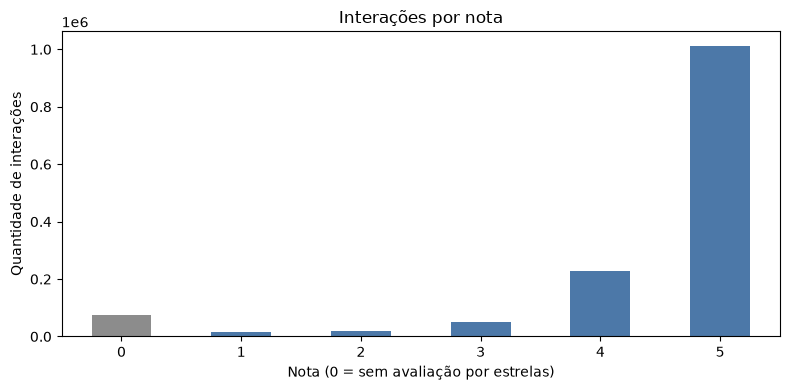

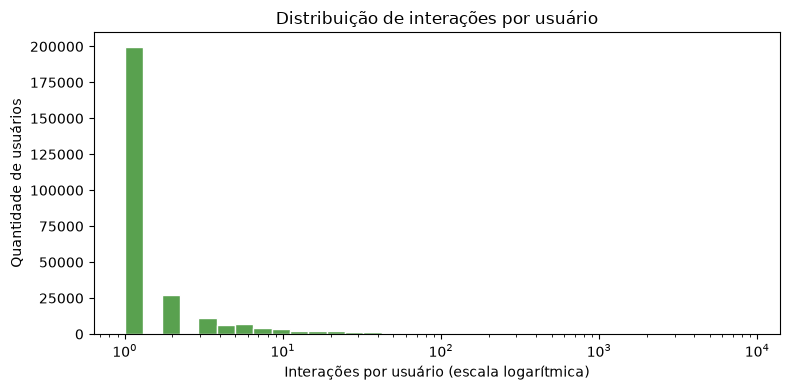

Mediana de interações por usuário: 1.0
Usuários com pelo menos 50 interações: 3427


In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
rating_counts.plot(kind='bar', ax=ax, color=['#8c8c8c'] + ['#4c78a8'] * 5)
ax.set_title('Interações por nota')
ax.set_xlabel('Nota (0 = sem avaliação por estrelas)')
ax.set_ylabel('Quantidade de interações')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
max_interactions = max(2, int(user_interactions.max()))
bins = np.logspace(0, np.log10(max_interactions), 35)
ax.hist(user_interactions, bins=bins, color='#59a14f', edgecolor='white')
ax.set_xscale('log')
ax.set_title('Distribuição de interações por usuário')
ax.set_xlabel('Interações por usuário (escala logarítmica)')
ax.set_ylabel('Quantidade de usuários')
plt.tight_layout()
plt.show()

print('Mediana de interações por usuário:', float(user_interactions.median()))
print('Usuários com pelo menos 50 interações:', int(user_interactions.ge(50).sum()))

## Categorias, ingredientes e tempo de preparo

As categorias são contadas no catálogo completo. Ingredientes e durações são examinados em uma amostra aleatória reprodutível de até 20 mil receitas para limitar o custo de processamento. O gráfico de duração limita apenas a visualização ao percentil 99; não altera os valores nem o filtro do aplicativo.

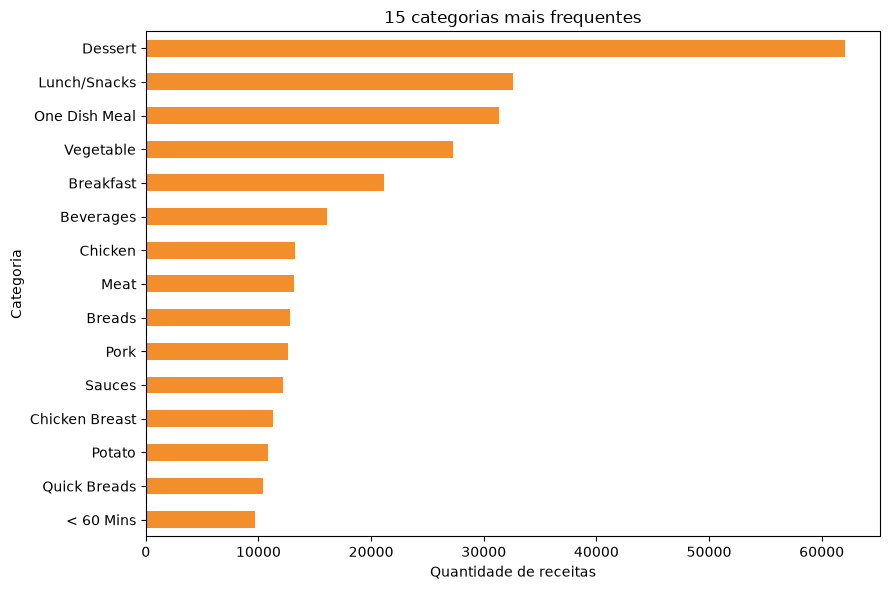

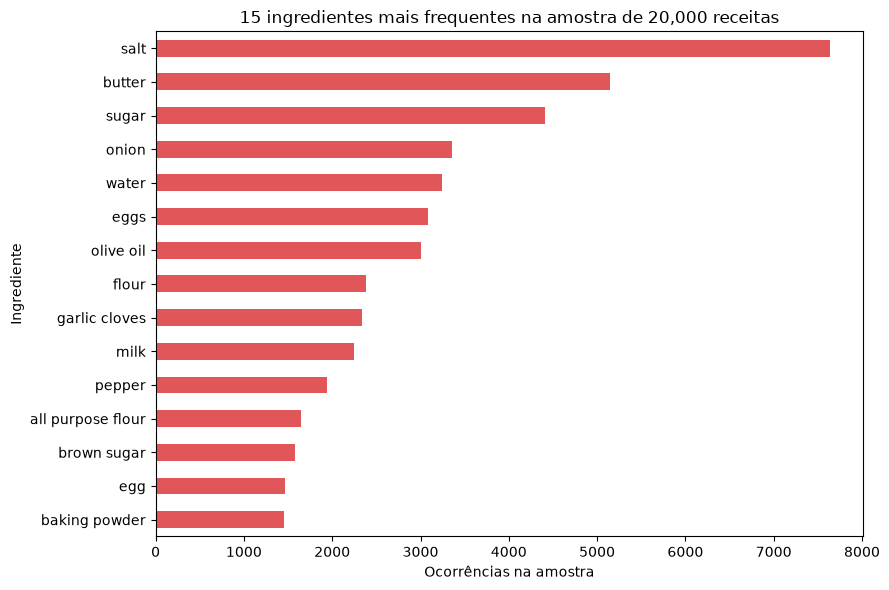

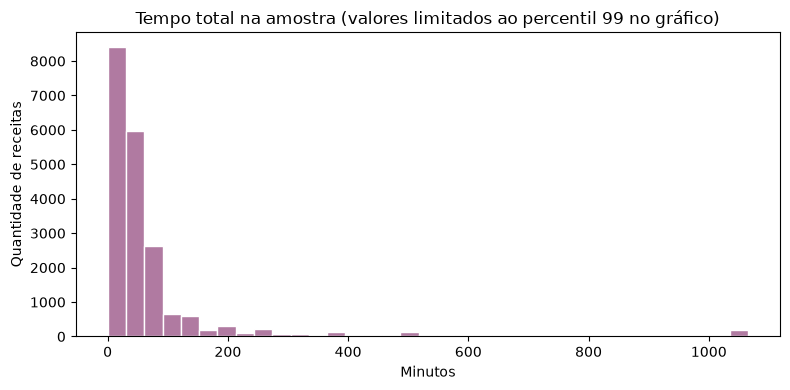

Mediana de TotalTime na amostra, em minutos: 40.0
Percentil 99 de TotalTime na amostra, em minutos: 1065.149999999976


In [3]:
categories = recipes['RecipeCategory'].dropna().astype(str).str.strip()
top_categories = categories[categories.ne('')].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
top_categories.plot(kind='barh', ax=ax, color='#f28e2b')
ax.set_title('15 categorias mais frequentes')
ax.set_xlabel('Quantidade de receitas')
ax.set_ylabel('Categoria')
plt.tight_layout()
plt.show()

sample_size = min(20_000, len(recipes))
recipe_sample = recipes.sample(n=sample_size, random_state=42)
ingredient_counts = Counter(
    ingredient
    for values in recipe_sample['RecipeIngredientParts']
    for ingredient in coerce_ingredient_list(values)
)
top_ingredients = pd.Series(ingredient_counts).sort_values(ascending=False).head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
top_ingredients.plot(kind='barh', ax=ax, color='#e15759')
ax.set_title(f'15 ingredientes mais frequentes na amostra de {sample_size:,} receitas')
ax.set_xlabel('Ocorrências na amostra')
ax.set_ylabel('Ingrediente')
plt.tight_layout()
plt.show()

sample_durations = recipe_sample['TotalTime'].map(parse_duration_to_minutes).dropna()
if not sample_durations.empty:
    upper_limit = float(sample_durations.quantile(0.99))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(sample_durations.clip(upper=upper_limit), bins=35, color='#b07aa1', edgecolor='white')
    ax.set_title('Tempo total na amostra (valores limitados ao percentil 99 no gráfico)')
    ax.set_xlabel('Minutos')
    ax.set_ylabel('Quantidade de receitas')
    plt.tight_layout()
    plt.show()
    print('Mediana de TotalTime na amostra, em minutos:', float(sample_durations.median()))
    print('Percentil 99 de TotalTime na amostra, em minutos:', upper_limit)
else:
    print('A amostra não possui durações válidas em TotalTime.')

## Conclusões

- A distribuição das notas deve ser interpretada separando ratings 1–5 de interações com rating 0; o valor 0 não indica avaliação negativa.
- Compare a mediana com a média e observe a escala logarítmica para identificar a concentração de usuários com poucas interações e a cauda longa de históricos maiores.
- As categorias e os ingredientes mostram quais metadados estão disponíveis para a recomendação baseada em conteúdo. Os ingredientes e tempos exibidos nos gráficos vêm de uma amostra reprodutível.
- Valores ausentes nos campos textuais são tratados no pré-processamento do projeto. Durações extremas podem distorcer médias e por isso o gráfico limita a visualização, não os dados.
- Esta análise descreve o dataset e não demonstra, por si só, a qualidade das recomendações nem substitui a avaliação com dados de teste.